# Практикум 1, часть 2. Онтология и машина вывода

Курс «От интеллектуального поиска к интеллектуальным агентам», ВМК МГУ.

**Что мы делаем и зачем.** В первой части требование 6.2 было строкой кода внутри инструмента: агент видел только итог проверки. Здесь положение, журнал и статья P2 записаны как онтология, то есть как данные, и выводы из них делает машина вывода. Так знание о требованиях становится читаемым, объяснимым и проверяемым на противоречия. Ваше задание 2 делает то же для вашей области. Онтология лежит в файле `data/review.owl`: его сохранил блокнот лекции 2.

| Пример | Что делаем | Вопрос до запуска |
|---|---|---|
| 4а | транзитивное свойство | записано 4 зависимости. Сколько будет после вывода? |
| 4б | правило в данных | где теперь записано требование 6.2? |
| 4в | граница машины вывода | заметит ли она статью с одной рецензией? |
| 4г | строка журнала с ошибкой | что случится, если в поле «рецензент» записать организацию? |
| 5 | агент с онтологией | что ответит агент на испорченных данных? |

Для примеров нужна Java: машина вывода Pellet написана на ней.

In [1]:
import sys; sys.path.insert(0, "agent")   # ядро агента, инструменты и выбор модели лежат в agent/
import json, os, re, pandas as pd
from llm_local import pick_llm, run_live_or_record
import agent_l1 as a            # корпус и правила над журналом, для сравнения
import agent_l2 as b            # онтология, машина вывода, три инструмента
import viz

pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 170)
LLM, note = pick_llm()
onto = b.onto
print("модель:", note)
print("онтология:", len(list(onto.classes())), "классов,", len(list(onto.individuals())), "индивидов,",
      len(list(onto.object_properties())), "объектных свойств")

модель: Ollama не отвечает или моделей нет: показываем записи, инструменты работают по-настоящему
онтология: 12 классов, 69 индивидов, 10 объектных свойств


## Что такое логический вывод: три строки

Прежде чем звать машину вывода, посмотрим на сам механизм. Записаны два факта и одно правило.
Из них получается третий факт, которого никто не записывал. Это и есть вывод: операция над записями,
которую может выполнять программа.

In [2]:
факты = {("зависит_от", "R65", "R64"), ("зависит_от", "R64", "R63")}        # записано
правило = "если x зависит_от y и y зависит_от z, то x зависит_от z"            # транзитивность

def шаг(факты):
    новые = {("зависит_от", x, z) for (_, x, y) in факты for (_, y2, z) in факты if y == y2}
    return новые - факты

print("записано:", sorted(факты))
новые = шаг(факты)
print("выведено:", sorted(новые), "  <- по правилу:", правило)
print("ещё шаг:  ", sorted(шаг(факты | новые)) or "новых фактов нет, неподвижная точка")

записано: [('зависит_от', 'R64', 'R63'), ('зависит_от', 'R65', 'R64')]
выведено: [('зависит_от', 'R65', 'R63')]   <- по правилу: если x зависит_от y и y зависит_от z, то x зависит_от z
ещё шаг:   новых фактов нет, неподвижная точка


Так работает машина вывода на всей онтологии: правила применяются к фактам, пока появляются новые факты.
На лекции 2 это называлось замыканием по правилам. Дальше ту же работу делает Pellet над `review.owl`:
правила там заданы аксиомами (транзитивность, иерархия, правило 6.2).

## Что записано в онтологии

Классы взяты из карты знаний, индивиды из корпуса и журнала.

In [3]:
for c in onto.classes():
    parents = ", ".join(p.name for p in c.is_a if hasattr(p, "name"))
    print(f"{c.name:18} ⊑ {parents:12} индивидов: {len(list(c.instances()))}")

Положение          ⊑ Объект       индивидов: 31
Рецензия           ⊑ Объект       индивидов: 14
Статья             ⊑ Объект       индивидов: 8
Рецензент          ⊑ Объект       индивидов: 6
Организация        ⊑ Объект       индивидов: 4
Требование         ⊑ Положение    индивидов: 14
Утверждение        ⊑ Объект       индивидов: 3
Доказательство     ⊑ Объект       индивидов: 3
Объект             ⊑ Thing        индивидов: 69
Раздел             ⊑ Положение    индивидов: 6
Термин             ⊑ Положение    индивидов: 11
БазовоеПоложение   ⊑ Положение    индивидов: 0


## Пример 5а. Одно слово вместо запроса пути

Свойство `зависит_от` объявлено транзитивным. Посмотрим на требование 6.5 до запуска машины вывода.

**Прогноз.** Записано 4 зависимости. Сколько их будет после вывода?

In [4]:
R65 = onto.R65
print("зависит_от транзитивно:", any(k.__name__ == "TransitiveProperty" for k in onto.зависит_от.is_a))
written = sorted(x.name for x in R65.зависит_от)
print("записано:", len(written), written)

зависит_от транзитивно: True
записано: 4 ['R61', 'R64', 'S06', 'T10']


In [5]:
b.reason()                                  # запуск машины вывода
inferred = sorted(x.name for x in R65.зависит_от)
print("непротиворечива:", b.state["непротиворечива"])
print("после вывода:", len(inferred), inferred)
print("выведено машиной:", sorted(set(inferred) - set(written)))

непротиворечива: True
после вывода: 14 ['R61', 'R63', 'R64', 'S01', 'S03', 'S06', 'T01', 'T04', 'T05', 'T06', 'T07', 'T08', 'T09', 'T10']
выведено машиной: ['R63', 'S01', 'S03', 'T01', 'T04', 'T05', 'T06', 'T07', 'T08', 'T09']


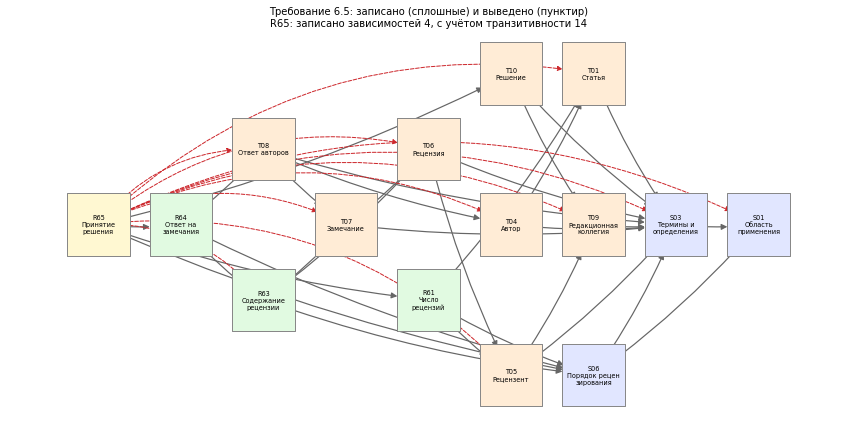

In [6]:
_ = viz.draw_deps(a.corpus, "R65", show_inferred=True, title="Требование 6.5: записано (сплошные) и выведено (пунктир)")

**Что увидели.** То же число 14, что дал запрос пути в первой части. Запроса никто не писал: машина получила зависимости из одного слова о свойстве отношения.

**В задании 2** это пункт «один выведенный факт»: записано, выведено, основание.

## Пример 5б. Правило в данных

Требование 6.2 записано в онтологии правилом: пять условий и заключение.

In [7]:
for r in onto.rules():
    print(str(r).replace("review.", "").replace("), ", "),\n  ").replace(" -> ", "\n-> "))

Рецензия(?r),
  на_статью(?r, ?s),
  рецензент(?r, ?p),
  из_организации(?p, ?o),
  организация_авторов(?s, ?o)
-> нарушает(?s, R62)


In [8]:
print(json.dumps(b.infer("P3"), ensure_ascii=False, indent=1))

{
 "статья": "P3",
 "выведено": [
  {
   "факт": "P3 нарушает R62 (6.2 Независимость рецензента)",
   "правило": "правило 6.2 (SWRL)"
  }
 ],
 "организация_авторов": [
  "ФИЦ_ИУ"
 ]
}


В коде инструмента `infer` сравнения организаций нет. Он читает у статьи свойство `нарушает`, которое записала машина вывода. Заключение правила ссылается на индивид R62, поэтому у нарушенного требования можно спросить его зависимости:

In [9]:
print(json.dumps(b.graph_deps("R62"), ensure_ascii=False, indent=1))

{
 "положение": "R62",
 "зависит_от": [
  "S01 Раздел 1. Область применения",
  "S03 Раздел 3. Термины и определения",
  "S06 Раздел 6. Порядок рецензирования",
  "T01 Статья",
  "T04 Автор",
  "T05 Рецензент",
  "T09 Редакционная коллегия"
 ],
 "основание": "транзитивность зависит_от"
}


## Пример 5в. Чего машина вывода не видит

**Прогноз.** У статьи P4 одна рецензия при норме две. Сообщит ли об этом машина вывода?

In [10]:
rules = {r["статья"]: r["причина"] for r in a.check_rules()}
rows = []
for name in sorted(rules):
    art = onto[name]
    rows.append({"статья": name,
                 "вывод машины": ", ".join(x.name for x in art.нарушает) or "—",
                 "правила над журналом (часть 1)": rules[name]})
pd.DataFrame(rows)

,статья,вывод машины,правила над журналом (часть 1)
0,P1,—,—
1,P2,—,—
2,P3,R62,6.2 (рецензент не из организации авторов)
3,P4,—,"6.1 (не менее двух сданных рецензий), 6.5 (есть ответ авторов на замечания)"
4,P5,—,6.6 (рецензии сданы в 21 день)
5,P6,—,6.5 (есть ответ авторов на замечания)
6,P7,—,—
7,P8,—,"6.1 (не менее двух сданных рецензий), 6.5 (есть ответ авторов на замечания)"


**Что увидели.** Машина вывода нашла нарушение требования 6.2 у статьи P3. О статьях P4, P5, P6, P8 она молчит.

Причина в открытом мире. Отсутствие записи о второй рецензии не означает, что рецензии нет. Сравнение дат относится к проверке данных. Машина вывода отвечает на вопрос «что следует из записанного». Вопрос «всё ли записано и верны ли значения» решает проверка данных, это лекция 3.

## Пример 5г. Строка журнала с ошибкой

В журнал добавляется рецензия на статью P8. В поле «рецензент» по ошибке записана организация ФИЦ ИУ.

**Прогноз.** Что произойдёт: (а) ошибка при записи, (б) ничего, (в) машина вывода сообщит о противоречии?

In [11]:
bad = b.add_error_row()          # Python принимает запись без возражений
res = b.check_consistency()
print("непротиворечива:", res["непротиворечива"])
for part in re.split(r"\s(?=рец_P9|рецензент range|ФИЦ_ИУ type)", res.get("объяснение", "")):
    print("  ", part.strip())

непротиворечива: False
   Explanation(s): 1) DisjointClasses(Доказательство Организация Положение Рецензент Рецензия Статья Утверждение)
   рец_P9_ошибка рецензент ФИЦ_ИУ
   рецензент range Рецензент
   ФИЦ_ИУ type Организация


Четыре участника противоречия:

1. факт из ошибочной строки: рецензентом указан ФИЦ_ИУ.
2. область значений свойства `рецензент`: значит, ФИЦ_ИУ является рецензентом.
3. тип индивида: ФИЦ_ИУ является организацией.
4. классы «Рецензент» и «Организация» не пересекаются.

Каждое утверждение по отдельности допустимо. Противоречие возникает из их сочетания. Пока ошибка на месте, инструменты выводов не выдают:

In [12]:
print(b.infer("P3"))
b.remove_error_row(bad)
print("после удаления строки:", b.check_consistency())

{'ошибка': 'запись противоречива, выводы недоступны'}
после удаления строки: {'непротиворечива': True}


**В задании 2** это пункт «разбор одного противоречия»: что внесено, что сообщила машина, как исправлено.

## Пример 6. Агент с онтологией

Цикл агента прежний. Изменились инструменты и инструкция.

In [13]:
print("ИНСТРУКЦИЯ\n" + b.SYSTEM + "\n\nИНСТРУМЕНТЫ")
for t in b.TOOLS:
    f = t["function"]
    print(f"  {f['name']:18} {f['description']}")

ИНСТРУКЦИЯ
Ты ассистент редактора сборника. Сначала вызови check_consistency. Если запись противоречива, сообщи об этом с пометкой [противоречие в данных] и не делай выводов о статьях. Иначе отвечай только по результатам инструментов. Помечай части ответа: [выведено: правило], [найдено: инструмент], [не подтверждено].

ИНСТРУМЕНТЫ
  infer              Факты о статье, выведенные машиной вывода по онтологии, с указанием правила.
  graph_deps         От каких положений зависит данное положение (с учётом транзитивности).
  check_consistency  Проверка непротиворечивости записи журнала и положения.


In [14]:
PLAN_1 = [("check_consistency", {}), ("infer", {"article": "P3"}), ("graph_deps", {"doc_id": "R62"})]
RECORD_1 = ("[запись ответа модели]\n"
            "Запись непротиворечива [найдено: check_consistency]. Статья P3 нарушает требование 6.2 "
            "«Независимость рецензента» [выведено: правило 6.2]. Требование 6.2 опирается на раздел 6, раздел 3, "
            "раздел 1 и термины Рецензент, Автор, Статья, Редакционная коллегия [найдено: graph_deps]. "
            "О требованиях 6.1 и 6.6 инструменты сведений не дали [не подтверждено].")
print("=== Прогон 1: вывод ===")
_ = run_live_or_record(LLM, b.QUESTION, b.SYSTEM, b.TOOLS, b.IMPL, PLAN_1, RECORD_1)

=== Прогон 1: вывод ===
[модели нет: порядок вызовов и текст ответа взяты из записи, результаты инструментов настоящие]
[1] модель вызвала check_consistency({})
    <- {"непротиворечива": true}
[2] модель вызвала infer({'article': 'P3'})
    <- {"статья": "P3", "выведено": [{"факт": "P3 нарушает R62 (6.2 Независимость рецензента)", "правило": "правило 6.2 (SWRL)"}], "организация_авторов": ["ФИЦ_ИУ"]}
[3] модель вызвала graph_deps({'doc_id': 'R62'})
    <- {"положение": "R62", "зависит_от": ["S01 Раздел 1. Область применения", "S03 Раздел 3. Термины и определения", "S06 Раздел 6. Порядок рецензирования", "T01 Стат…
[4] ответ модели:
[запись ответа модели]
Запись непротиворечива [найдено: check_consistency]. Статья P3 нарушает требование 6.2 «Независимость рецензента» [выведено: правило 6.2]. Требование 6.2 опирается на раздел 6, раздел 3, раздел 1 и термины Рецензент, Автор, Статья, Редакционная коллегия [найдено: graph_deps]. О требованиях 6.1 и 6.6 инструменты сведений не дали [не под

**Прогноз.** Тот же вопрос, в журнале строка с ошибкой. Что ответит агент?

In [15]:
PLAN_2 = [("check_consistency", {})]
RECORD_2 = ("[запись ответа модели]\n"
            "Запись журнала противоречива [противоречие в данных]: индивид ФИЦ_ИУ указан рецензентом "
            "в строке рец_P9_ошибка и одновременно является организацией. "
            "Выводы о статьях не делаю до исправления строки.")
print("=== Прогон 2: журнал со строкой с ошибкой ===")
bad = b.add_error_row()
_ = run_live_or_record(LLM, b.QUESTION, b.SYSTEM, b.TOOLS, b.IMPL, PLAN_2, RECORD_2)
b.remove_error_row(bad)

=== Прогон 2: журнал со строкой с ошибкой ===
[модели нет: порядок вызовов и текст ответа взяты из записи, результаты инструментов настоящие]
[1] модель вызвала check_consistency({})
    <- {"непротиворечива": false, "объяснение": "Explanation(s): 1) DisjointClasses(Доказательство Организация Положение Рецензент Рецензия Статья Утверждение) рец_P9_…
[2] ответ модели:
[запись ответа модели]
Запись журнала противоречива [противоречие в данных]: индивид ФИЦ_ИУ указан рецензентом в строке рец_P9_ошибка и одновременно является организацией. Выводы о статьях не делаю до исправления строки.

[время: 1.3 с]


**Что увидели.** В первом прогоне каждый факт ответа приходит с правилом или инструментом, и агент честно сообщает, о чём сведений нет. Во втором прогоне агент останавливается и называет причину. Агент первой части на такой строке выдал бы обычный уверенный ответ.

## Вопрос

Впишите вопрос и запустите ячейку. Нужна модель. Без неё ячейка показывает, что вернут инструменты.

In [16]:
ВОПРОС = "Нарушает ли статья P1 требования положения?"
if LLM:
    from agent_core import run_agent
    try:
        run_agent(ВОПРОС, LLM, b.SYSTEM, b.TOOLS, b.IMPL)
    except Exception as e:
        print(f"[модель не ответила: {type(e).__name__}]. Что вернут инструменты на этот вопрос:")
        print(b.check_consistency()); print(b.infer("P1"))
else:
    print("модели нет. Что вернут инструменты на этот вопрос:")
    print(b.check_consistency()); print(b.infer("P1"))

модели нет. Что вернут инструменты на этот вопрос:
{'непротиворечива': True}
{'статья': 'P1', 'выведено': [], 'организация_авторов': ['МГУ']}


## Что повторить самостоятельно

1. Запустить этот блокнот. Открыть `data/review.owl` в Protégé.
2. Внести свою ошибку в данные и прочитать объяснение машины вывода.
3. Перейти к блокноту `practice_3_tasks.ipynb`: там онтология строится с нуля на маленькой области.